# Metrics and Logistic Regression Lab

## Introduction

In the healthcare industry, detecting early signs of chronic diseases like diabetes is a critical task for data analysts and junior data scientists working with medical records. Consider a scenario where a hospital's data science team is tasked with improving patient risk assessments for diabetes. Currently, doctors rely on a combination of lab results, medical history, and risk factors to identify at-risk patients. However, this manual process is time-consuming and error-prone.

To address this challenge, the hospital plans to implement a data-driven approach to predict the likelihood of diabetes using patient health metrics such as glucose levels, blood pressure, and BMI. A junior data scientist is given a dataset of past patient records and must build a predictive model to classify whether a patient has diabetes.

The problem-solving process begins with data exploration to understand the available features and ensure the dataset is clean and structured correctly. Key health indicators are identified, and the data is standardized to ensure consistency across the model. The dataset is then split into training and testing sets to assess model performance objectively. A logistic regression model is selected, trained, and evaluated using performance metrics such as accuracy, precision, and recall. Finally, a confusion matrix is visualized to interpret the model's effectiveness in distinguishing between diabetic and non-diabetic patients.

By following this process, the junior data scientist ensures the hospital can deploy a reliable, scalable system for early diabetes detection, reducing the workload for healthcare professionals and improving patient outcomes.

### Step 0: Installing the Faraway Package, Importing Libraries, and Loading the Data

- Install the necessary package, `faraway`, to access the dataset. 
- Import the essential libraries, including `pandas` and `numpy` for data manipulation, `matplotlib` and `seaborn` for visualization, and `sklearn` modules for preprocessing, model training, and evaluation.
- Load the Pima Indians Diabetes dataset from the `faraway` package. 
- Convert the target variable, which indicates whether a patient has diabetes, into an integer format to ensure proper classification.

In [1]:
# Run `pip install` only if the Faraway package is not installed:
# ! pip install faraway

In [2]:
# CodeGrade step0

# Import any useful libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score

# Import the dataset from Faraway:
from faraway.datasets import pima

# Load the dataset:
data = pima.load()

# Convert the `diabetes` column to an `int` type to represent classes 0 and 1.
# Remove the handful of 2s (unknown) in the data:
data["diabetes"] = data["diabetes"].astype(int)
data = data[data["diabetes"] != 2]

### Step 1: Data Exploration

- Display the first few rows to examine the dataset's structure.
- Inspect the dataset's metadata, including column types and missing values.
- Check the dataset's shape to determine the number of rows and columns.

In [3]:
# CodeGrade step1

# Display the first few rows:
display(data.head())

# Display basic information:
data.info()

# Check for missing values:
display(data.isnull().sum())

# Return the shape of the data:
data.shape

,pregnant,glucose,diastolic,triceps,insulin,bmi,diabetes,age,test
0,6,148,72,35,0,33.6,0,50,1
1,1,85,66,29,0,26.6,0,31,0
2,8,183,64,0,0,23.3,0,32,1
3,1,89,66,23,94,28.1,0,21,0
5,5,116,74,0,0,25.6,0,30,0


<class 'pandas.core.frame.DataFrame'>
Index: 764 entries, 0 to 767
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pregnant   764 non-null    int64  
 1   glucose    764 non-null    int64  
 2   diastolic  764 non-null    int64  
 3   triceps    764 non-null    int64  
 4   insulin    764 non-null    int64  
 5   bmi        764 non-null    float64
 6   diabetes   764 non-null    int64  
 7   age        764 non-null    int64  
 8   test       764 non-null    int64  
dtypes: float64(1), int64(8)
memory usage: 59.7 KB


pregnant     0
glucose      0
diastolic    0
triceps      0
insulin      0
bmi          0
diabetes     0
age          0
test         0
dtype: int64

(764, 9)

### Step 2: Feature Selection, Data Scaling, and Data Splitting

- Choose the independent variables (features) and define the target variable.
- Standardize the features using `StandardScaler()` to ensure a mean of 0 and a standard deviation of 1.
- Split the dataset into training (80%) and testing (20%) sets, setting a random seed for reproducibility.
- Verify the dimensions of the training and testing sets.

In [4]:
# CodeGrade step2

# Define the features (X) and the target variable (y):
X = data[["glucose", "insulin", "bmi", "age"]]
y = data["diabetes"]

# Check the distribution of the target classes:
display(y.value_counts())
display(y.value_counts(normalize = True) * 100)

# Just like in the previous Module 2 lab, we should split the data BEFORE
# scaling it in order to prevent data leakage, even though the instructions
# seem to indicate scaling before splitting.
# Split the dataset into training (80%) and testing (20%) sets:
# The target variable, y, is imbalanced, with 717 zeros and only 47 ones. In
# order to keep this ratio approximately the same in our training and testing
# sets, we'll use stratified splitting.
seed = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, 
                                                    random_state = seed, stratify = y)

# Scale the features:
scaler = StandardScaler()

# Fit the scaler on the training data only:
X_train_scaled = scaler.fit_transform(X_train)

# Use this same fitted scaler to transform the testing data:
X_test_scaled = scaler.transform(X_test)

# Return the shapes of the training and testing sets:
X_train_scaled.shape, X_test_scaled.shape, y_train.shape, y_test.shape

diabetes
0    717
1     47
Name: count, dtype: int64

diabetes
0    93.848168
1     6.151832
Name: proportion, dtype: float64

((611, 4), (153, 4), (611,), (153,))

### Step 3: Model Training

- Create a logistic regression model with an increased iteration limit to ensure convergence.
- Train the model using the training data.
- Generate predictions for the test set, including both probability scores and final class labels.

In [5]:
# CodeGrade step3

# Train the logistic regression model:
model = LogisticRegression(max_iter = 1000).fit(X_train_scaled, y_train)

# Predict the probability of each patient in `X_test_scaled` having diabetes
# (class 1):
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# Using these probabilities, and the threshold that prob ≥ 0.5 --> 1/True,
# predict the diagnosis for each patient in `X_test_scaled`:
y_pred = model.predict(X_test_scaled)

# Print the first ten elements of both of these arrays:
print(f"First ten predicted probabilities: {y_pred_proba[0:10]}")
print(f"First ten predicted classes: {y_pred[0:10]}")

First ten predicted probabilities: [0.04842618 0.080447   0.04576153 0.05273184 0.06323505 0.05530943
 0.06217257 0.03372753 0.05005972 0.03434963]
First ten predicted classes: [0 0 0 0 0 0 0 0 0 0]


### Step 4: Model Evaluation

- Generate a confusion matrix to assess classification performance.
- Compute a classification report to review precision, recall, and F1-score for each class.

In [6]:
# CodeGrade step4

# Create a confusion matrix for the model:
cm = confusion_matrix(y_test, y_pred)

# Show it:
print(cm)

# Create a classification report for the model:
report = classification_report(y_test, y_pred)

# Show it:
print(report)

[[144   0]
 [  9   0]]
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       144
           1       0.00      0.00      0.00         9

    accuracy                           0.94       153
   macro avg       0.47      0.50      0.48       153
weighted avg       0.89      0.94      0.91       153



/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _

### Step 5: Visualization of Confusion Matrix

- Create a heatmap to visualize the confusion matrix.
- Ensure the visualization clearly shows the number of correct and incorrect predictions for each class.

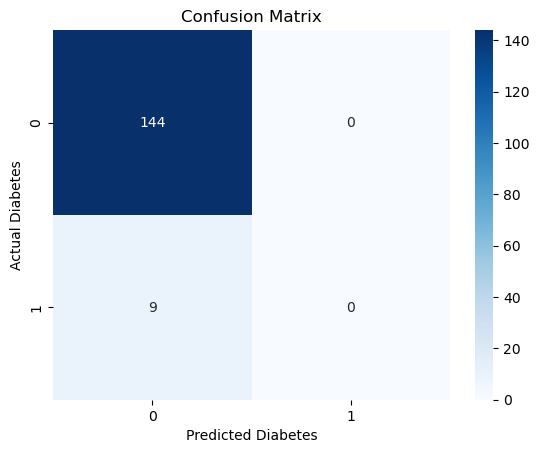

(0.5864197530864197, 8.444444444444443, 10.0, inf)

In [7]:
# CodeGrade step5

# Visualize the confusion matrix:
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Diabetes")
plt.ylabel("Actual Diabetes")
plt.show()

# Calculate the ROC curve by finding fpr, tpr, and thresholds:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Calculate the AUC:
auc = roc_auc_score(y_test, y_pred_proba)

# Return:
auc, sum(fpr), sum(tpr), sum(thresholds)

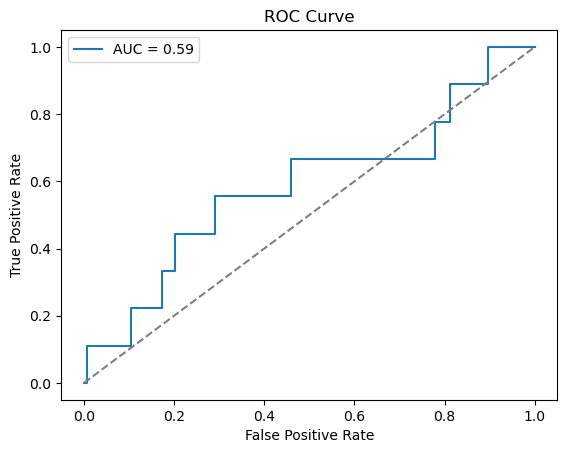

In [8]:
# Show the ROC Curve:
plt.plot(fpr, tpr, label = f"AUC = {auc:.2f}")
# Add a reference line for random guessing:
plt.plot([0, 1], [0, 1], linestyle = "--", color = "gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()